# 02 · SARSA

> Implementa SARSA (`SarsaAgent.update` en `src/agents.py`), **ajusta sus hiperparámetros** en los cuatro mercados con
> **el mismo protocolo que el 01** (validación, 3 semillas, etapas y parsimonia; D-0.4, D-2.3), mide el resultado final
> en test frente a los baselines y a Q-Learning, y analiza si la estrategia aprendida es la esperada. Guarda
> `results/02_sarsa.csv`, con el mismo esquema que `00_baselines.csv` y `01_qlearning.csv`, para el 04.

| § | Contenido | Qué sale de aquí |
|---|---|---|
| 0 | La regla de SARSA en una figura | En qué se diferencia de Q-Learning |
| 1 | Implementación y prueba | `update()` verificada a mano y orden *elegir A′ → actualizar* comprobado |
| 2 | Cómo ajustamos los hiperparámetros | El mismo procedimiento del 01 |
| 3 | Etapa 1 · tasa de aprendizaje α | α por mercado |
| 4 | Etapa 2 · factor de descuento γ | γ por mercado |
| 5 | Etapa 3 · exploración ε | Decaimiento y ε mínimo por mercado |
| 6 | Etapa 4 · número de episodios y convergencia | Episodios por mercado y velocidad de convergencia |
| 7 | Resultado final en test | `results/02_sarsa.csv` |
| 8 | ¿Es la estrategia esperada? | Política aprendida y un episodio por mercado |
| 9 | SARSA frente a Q-Learning con la misma configuración | ¿Quién converge antes y por qué? |
| 10 | Conclusiones | Decisiones y qué pasa al 04 |

Teoría: [`docs/teoria/02_td_sarsa_qlearning.md`](../docs/teoria/02_td_sarsa_qlearning.md) (§6 y §8). Resultados de
referencia: [`01_qlearning.ipynb`](01_qlearning.ipynb).

In [1]:
import os, sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display

from src.env import SimpleTradingEnv, discretize, n_states
from src.markets import MARKETS, make_prices
from src.agents import SarsaAgent, QLearningAgent, BuyHoldAgent, RandomAgent
from src.experiment import (train, evaluate, run_episode, summarize, save_results, quantile_edges, run_grid,
                            run_config, config_id, RESULTS_DIR, N_BINS, N_TEST, N_VAL, RESULT_COLUMNS)
from src.style import setup, savefig, AGENT_COLORS, MARKET_COLORS, MARKET_LABELS

setup()
pd.set_option("display.precision", 3)

QUICK = os.environ.get("NB_QUICK") == "1"     # prueba rápida del notebook: pocos episodios y una semilla
RECALCULAR = False                             # True = ignorar la caché de results/ y reentrenar todo
SEEDS = [0] if QUICK else [0, 1, 2]            # semillas de entrenamiento para el ajuste
SEEDS_FINAL = [0, 1] if QUICK else [0, 1, 2, 3, 4]
N_EP = 40 if QUICK else 500                    # episodios por defecto durante el ajuste
SUF = "_quick" if QUICK else ""
# Mismo punto de partida que el 01, para que la comparación sea justa
BASE = dict(agente="sarsa", n_bins=N_BINS, alpha=0.001, gamma=0.9, epsilon_decay=0.99,
            epsilon_min=0.01, n_episodes=N_EP, split="val")
baselines = pd.read_csv(RESULTS_DIR / "00_baselines.csv")
qlearning = pd.read_csv(RESULTS_DIR / "01_qlearning.csv")
qlearning_sem = pd.read_csv(RESULTS_DIR / "01_qlearning_semillas.csv")
print(f"{N_BINS} bins por cuantiles · ajuste en {N_VAL} series de validación · test final en {N_TEST} series"
      f" · semillas de ajuste {SEEDS}" + ("  [MODO RÁPIDO]" if QUICK else ""))

10 bins por cuantiles · ajuste en 100 series de validación · test final en 200 series · semillas de ajuste [0, 1, 2]


## 0. La regla de SARSA en una figura

SARSA mantiene la misma tabla $Q(s, a)$ que Q-Learning y la corrige con la misma forma de error TD (slides3 p29–p31).
Su nombre es la tupla que usa en cada actualización: $(S_t, A_t, R_{t+1}, S_{t+1}, A_{t+1})$.

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\,\big[\,\underbrace{R_{t+1} + \gamma\, Q(S_{t+1},A_{t+1})}_{\text{objetivo TD}} - Q(S_t,A_t)\,\big]$$

**La única diferencia con Q-Learning está en el objetivo.** Q-Learning usa $\max_a Q(S_{t+1}, a)$, la mejor acción del
estado siguiente, aunque luego no la ejecute. SARSA usa $Q(S_{t+1}, A_{t+1})$, **la acción que de verdad va a hacer**,
elegida con la misma ε-greedy con la que actúa. Por eso es *on-policy*: aprende el valor de la política que sigue,
**incluidos sus errores de exploración**. En *cliff walking* esto le lleva a una ruta más segura (slides3 p41–p43); aquí
cabe esperar que, mientras ε sea alto, valore peor las posiciones abiertas, porque cuenta con que alguna vez cerrará por
error y pagará comisión.

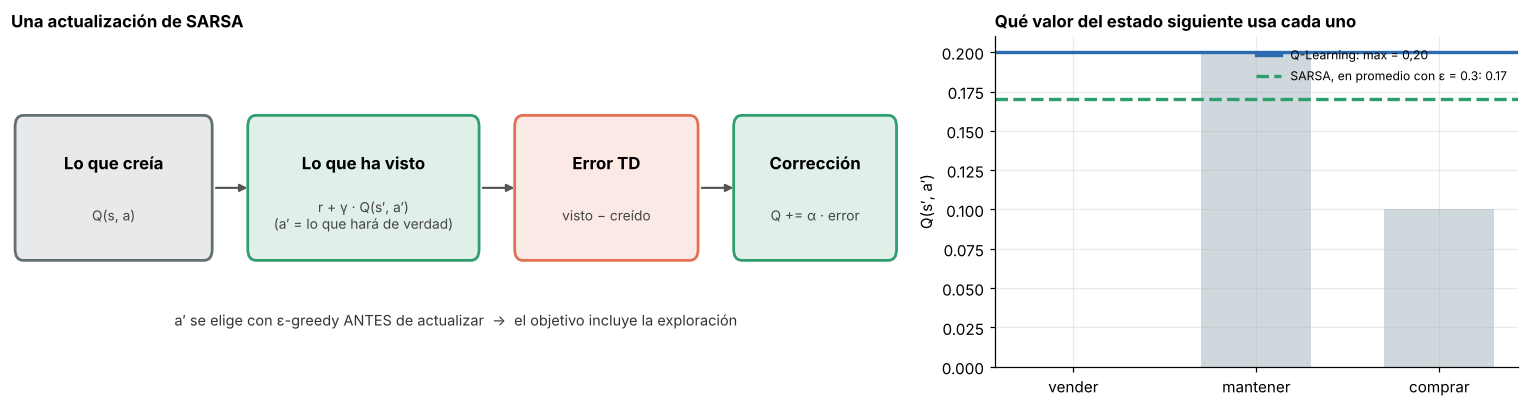

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
ax.set_xlim(0, 13); ax.set_ylim(0, 3.6); ax.axis("off")
def box(x, w, title, sub, color, y=1.2, h=1.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=color, alpha=0.15, ec="none"))
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc="none", ec=color, lw=1.8))
    ax.text(x + w / 2, y + h * 0.68, title, ha="center", va="center", fontsize=11, weight="bold")
    ax.text(x + w / 2, y + h * 0.3, sub, ha="center", va="center", fontsize=9, color="#444")
box(0.1, 2.8, "Lo que creía", "Q(s, a)", "#636E72")
box(3.5, 3.3, "Lo que ha visto", "r + γ · Q(s′, a′)\n(a′ = lo que hará de verdad)", AGENT_COLORS["sarsa"])
box(7.4, 2.6, "Error TD", "visto − creído", "#E17055")
box(10.6, 2.3, "Corrección", "Q += α · error", "#2F9E6E")
for x1, x2 in [(2.95, 3.5), (6.85, 7.4), (10.05, 10.6)]:
    ax.annotate("", (x2, 1.95), (x1, 1.95), arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.4))
ax.text(6.5, 0.45, "a′ se elige con ε-greedy ANTES de actualizar  →  el objetivo incluye la exploración",
        ha="center", fontsize=9.5, color="#333")
ax.set_title("Una actualización de SARSA", loc="left")

# Mismo estado siguiente, dos objetivos: Q(s′, ·) = [vender 0,00 · mantener 0,20 · comprar 0,10]
ax = axes[1]
q_next = np.array([0.0, 0.2, 0.1]); eps = 0.3
esperado_sarsa = (1 - eps) * q_next.max() + eps * q_next.mean()
ax.bar([0, 1, 2], q_next, color="#CFD8DC", width=0.6)
ax.axhline(q_next.max(), color=AGENT_COLORS["qlearning"], lw=2.2, label="Q-Learning: max = 0,20")
ax.axhline(esperado_sarsa, color=AGENT_COLORS["sarsa"], lw=2.2, ls="--",
           label=f"SARSA, en promedio con ε = {eps}: {esperado_sarsa:.2f}")
ax.set_xticks([0, 1, 2], ["vender", "mantener", "comprar"]); ax.set_ylabel("Q(s′, a′)")
ax.set_title("Qué valor del estado siguiente usa cada uno", loc="left"); ax.legend(loc="upper right", fontsize=8)
fig.tight_layout(); savefig(fig, "02_regla_sarsa"); plt.show()

## 1. Implementación y prueba

La regla está en `src/agents.py`, con $Q(\text{terminal}, \cdot) = 0$:

```python
def update(self, s, a, r, s2, a2, done):
    target = r if done else r + self.gamma * self.Q[s2, a2]
    self.Q[s, a] += self.alpha * (target - self.Q[s, a])
```

`run_episode` (en `src/experiment.py`) ya respeta el orden del pseudocódigo de slides3 p31 (D-2.1): como `SarsaAgent`
tiene `on_policy = True`, **elige $A'$ antes de actualizar** y luego **ejecuta exactamente esa $A'$**. Tres
comprobaciones: un paso a mano (y el mismo paso con Q-Learning, para ver la diferencia), que la acción usada en el
objetivo es la que se ejecuta después y que el paso terminal no tiene futuro.

In [3]:
ag = SarsaAgent(alpha=0.5, gamma=0.9)
ag.Q[3] = [0.0, 0.2, 0.1]                                    # en s′ la mejor acción vale 0,2, pero el agente hará comprar (0,1)
ag.update(s=0, a=2, r=0.01, s2=3, a2=2, done=False)
ql = QLearningAgent(alpha=0.5, gamma=0.9); ql.Q[3] = [0.0, 0.2, 0.1]
ql.update(s=0, a=2, r=0.01, s2=3, a2=None, done=False)
esperado = 0.5 * (0.01 + 0.9 * 0.1 - 0)
display(pd.DataFrame({"SARSA: Q(0, comprar)": [ag.Q[0, 2]], "a mano: 0,5·(0,01 + 0,9·0,1)": [esperado],
                      "coinciden": [np.isclose(ag.Q[0, 2], esperado)],
                      "Q-Learning (usa el max 0,2)": [ql.Q[0, 2]]}).style.hide(axis="index"))

ag.update(s=1, a=0, r=-0.001, s2=3, a2=1, done=True)        # paso final: no hay futuro
print(f"Paso terminal: Q(1, vender) = {ag.Q[1, 0]:+.5f} (= 0,5 · −0,001, sin término de futuro)")

class Espia(SarsaAgent):
    # Registra la a′ de cada actualización y las acciones que se ejecutan, para comprobar que coinciden
    def __init__(self, *a, **k):
        super().__init__(*a, **k); self.a2_usadas, self.ejecutadas = [], []
    def update(self, s, a, r, s2, a2, done):
        self.ejecutadas.append(a)
        if not done: self.a2_usadas.append(a2)
        super().update(s, a, r, s2, a2, done)
esp = Espia(edges=quantile_edges("reversion_media", N_BINS), epsilon=0.5, seed=0)
run_episode(SimpleTradingEnv(make_prices("reversion_media", 500, 0)), esp, learn=True)
ok = esp.a2_usadas == esp.ejecutadas[1:]
print(f"Acción usada en el objetivo = acción ejecutada en el paso siguiente en los {len(esp.a2_usadas)} pasos: {ok}")
assert ok

"SARSA: Q(0, comprar)","a mano: 0,5·(0,01 + 0,9·0,1)",coinciden,"Q-Learning (usa el max 0,2)"
0.050000,0.050000,True,0.095000


Paso terminal: Q(1, vender) = -0.00050 (= 0,5 · −0,001, sin término de futuro)
Acción usada en el objetivo = acción ejecutada en el paso siguiente en los 493 pasos: True


## 2. Cómo ajustamos los hiperparámetros

**Exactamente el procedimiento del 01** (D-0.4 y D-2.3), para que la comparación del 04 sea justa:

- se elige con **100 series de validación** y el test se usa una sola vez, al final;
- se ajusta **por mercado y por etapas**: α → γ → ε → episodios, con **3 semillas** por configuración y la **mediana
  entre semillas** de la mediana del retorno en validación como puntuación;
- **regla de parsimonia**: un valor nuevo solo sustituye al de partida si le gana en la mayoría de las semillas
  (comparando semilla a semilla) y tiene mejor mediana;
- **mismo punto de partida y mismas rejillas** que el 01 (α 0,001, γ 0,9, ε 0,99 / 0,01, 500 episodios).

Si SARSA acaba con hiperparámetros distintos a los de Q-Learning, se debe a los datos y no a haberlo ajustado de otra forma.

In [4]:
def grid(param_values, base_por_mercado, nombre):
    # Barre los valores de `param_values` ({param: [valores]}) sobre la config de cada mercado, con SEEDS
    cfgs = []
    for m in MARKETS:
        for combo in pd.MultiIndex.from_product(list(param_values.values()), names=list(param_values)):
            combo = combo if isinstance(combo, tuple) else (combo,)
            for s in SEEDS:
                cfgs.append({**base_por_mercado[m], **dict(zip(param_values, combo)), "mercado": m, "seed": s})
    return run_grid(cfgs, nombre + SUF, recompute=RECALCULAR)

def puntuar(df, params):
    # Mediana entre semillas de la mediana en validación, y operaciones medias
    return df.groupby(["mercado"] + params).agg(score=("retorno_mediana", "median"),
                                               ops=("n_trades", "mean")).reset_index()

def elegir(df, sc, params, base_por_mercado):
    # Mejor valor por mercado con la regla de parsimonia del 01
    nuevo = {}
    for m in MARKETS:
        base_vals = tuple(base_por_mercado[m][p] for p in params)
        d = df[df.mercado == m].copy(); d["combo"] = d[params].apply(tuple, axis=1)
        base_por_semilla = d[d.combo == base_vals].set_index("seed").retorno_mediana
        sub = sc[sc.mercado == m].copy(); sub["combo"] = sub[params].apply(tuple, axis=1)
        def gana(combo):
            cand = d[d.combo == combo].set_index("seed").retorno_mediana
            return (cand > base_por_semilla + 1e-9).sum() > len(SEEDS) / 2
        sub["elegible"] = [(c == base_vals) or gana(c) for c in sub.combo]
        fila = sub[sub.elegible].sort_values("score", ascending=False).iloc[0]
        nuevo[m] = {**base_por_mercado[m], **{p: fila[p] for p in params}}
    return nuevo

def fmt_ret(v, m):
    return f"x{1 + v:,.0f}" if m == "tendencia_ciclo" else f"{v:+.1%}"

def heatmap(sc, param, titulo, nombre_fig, etiquetas=None, elegido=None):
    # Mapa mercado × valor: color por posición dentro de cada mercado (verde = mejor), texto = mediana y ops
    vals = sorted(sc[param].unique())
    fig, ax = plt.subplots(figsize=(1.6 + 1.55 * len(vals), 3.6))
    for i, m in enumerate(MARKETS):
        sub = sc[sc.mercado == m].set_index(param).loc[vals]
        rng = sub.score.max() - sub.score.min()
        rel = (sub.score - sub.score.min()) / rng if rng > 1e-12 else pd.Series(0.5, index=sub.index)
        for j, v in enumerate(vals):
            ax.add_patch(plt.Rectangle((j, 3 - i), 1, 1, fc=plt.cm.RdYlGn(0.15 + 0.7 * rel.loc[v]), ec="white", lw=2))
            ops = sub.loc[v, "ops"]
            txt = fmt_ret(sub.loc[v, "score"], m) + ("\nno opera" if ops < 0.5 else f"\n{ops:.0f} ops")
            ax.text(j + 0.5, 3.5 - i, txt, ha="center", va="center", fontsize=8.5, weight="bold", color="#222")
            sel = None if elegido is None else elegido[m][param]
            if sel is not None and ((sel == v) if isinstance(v, str) else np.isclose(sel, v)):
                ax.add_patch(plt.Rectangle((j + 0.04, 3.04 - i), 0.92, 0.92, fc="none", ec="black", lw=2.2))
    ax.set_xlim(0, len(vals)); ax.set_ylim(0, 4); ax.grid(False)
    ax.set_xticks(np.arange(len(vals)) + 0.5, etiquetas or [str(v) for v in vals])
    ax.set_yticks(np.arange(4) + 0.5, [MARKET_LABELS[m] for m in reversed(list(MARKETS))])
    for s_ in ax.spines.values(): s_.set_visible(False)
    ax.tick_params(length=0); ax.set_title(titulo, loc="left")
    fig.tight_layout(); savefig(fig, nombre_fig); plt.show()

def tabla_elegidos(cfg_m, params):
    return pd.DataFrame({MARKET_LABELS[m]: {p: cfg_m[m][p] for p in params} for m in MARKETS}).T

## 3. Etapa 1 · Tasa de aprendizaje α

Misma rejilla que el 01. El recuadro negro marca el valor elegido para cada mercado y el color compara solo dentro de cada fila.

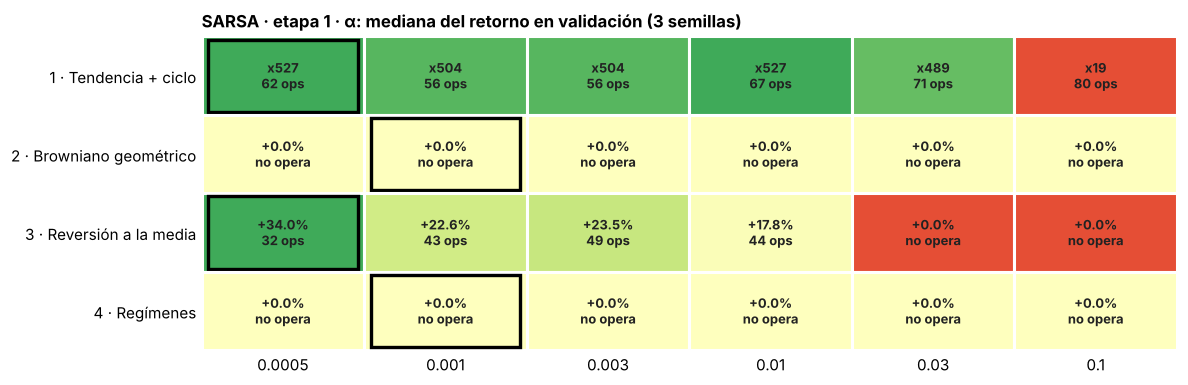

,alpha
1 · Tendencia + ciclo,0.000500
2 · Browniano geométrico,0.001000
3 · Reversión a la media,0.000500
4 · Regímenes,0.001000


In [5]:
ALPHAS = [0.0005, 0.001, 0.003, 0.01, 0.03, 0.1]
base0 = {m: dict(BASE) for m in MARKETS}
df_a, _, _ = grid({"alpha": ALPHAS}, base0, "02_grid_alpha")
sc_a = puntuar(df_a, ["alpha"])
cfg1 = elegir(df_a, sc_a, ["alpha"], base0)
heatmap(sc_a, "alpha", "SARSA · etapa 1 · α: mediana del retorno en validación (3 semillas)", "02_ajuste_alpha", elegido=cfg1)
display(tabla_elegidos(cfg1, ["alpha"]).style.set_caption("α elegido por mercado"))

**Igual que en Q-Learning, α tiene que ser pequeño, y SARSA lo prefiere aún más pequeño.** En reversión a la media,
α = 0,0005 sube la validación de +22,6 % a **+34,0 %** y gana en 2 de las 3 semillas; con 0,03 y 0,1 deja de operar. En el
mercado 1 hay una meseta (x503–x526 entre 0,0005 y 0,01) que se hunde con 0,1 (x19), y 0,0005 se queda porque gana a
0,001 en la mayoría de semillas. En los mercados 2 y 4 el agente no opera con ningún α.

Una explicación coherente: el objetivo de SARSA usa la acción **muestreada** $A'$ (a veces aleatoria) en lugar del
máximo, así que tiene **más varianza** que el de Q-Learning y agradece promediar más (α menor).

## 4. Etapa 2 · Factor de descuento γ

En el 01, Q-Learning eligió γ = 0 en el mercado 1 y γ = 0,5 en el 3. En SARSA γ tiene un efecto extra: con γ alto, el
objetivo arrastra más pasos de la política ε-greedy, **incluidas sus operaciones exploratorias**, así que cabe esperar que
penalice más estar dentro.

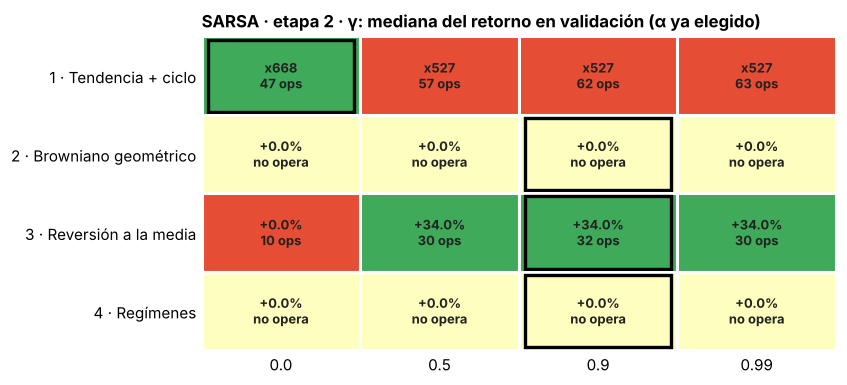

,alpha,gamma
1 · Tendencia + ciclo,0.000500,0.000000
2 · Browniano geométrico,0.001000,0.900000
3 · Reversión a la media,0.000500,0.900000
4 · Regímenes,0.001000,0.900000


In [6]:
GAMMAS = [0.0, 0.5, 0.9, 0.99]
df_g, _, _ = grid({"gamma": GAMMAS}, cfg1, "02_grid_gamma")
sc_g = puntuar(df_g, ["gamma"])
cfg2 = elegir(df_g, sc_g, ["gamma"], cfg1)
heatmap(sc_g, "gamma", "SARSA · etapa 2 · γ: mediana del retorno en validación (α ya elegido)", "02_ajuste_gamma", elegido=cfg2)
display(tabla_elegidos(cfg2, ["alpha", "gamma"]).style.set_caption("α y γ elegidos por mercado"))

**El mercado 1 vuelve a elegir γ = 0 (el agente miope)**, como Q-Learning: x668 frente a x527 en validación, ganando en las
3 semillas. Con un ruido del 10 % por paso, el valor de los pasos lejanos se estima mal y la tendencia actual ya predice
el siguiente retorno (01 §4). En reversión, γ = 0 casi no opera (el rebote tarda varios pasos) y **0,5, 0,9 y 0,99 dan
lo mismo** (+34 %), así que por parsimonia se mantiene 0,9. Q-Learning había elegido 0,5: la diferencia no es de fondo,
es que en SARSA 0,5 no supera a 0,9 en la mayoría de semillas.

## 5. Etapa 3 · Exploración ε

ε es el hiperparámetro que más debería distinguir a SARSA de Q-Learning, porque entra en su objetivo: mientras ε sea
grande, SARSA aprende el valor de una política que se equivoca a menudo. Mismos calendarios que el 01 (decaimiento
por episodio 0,98 / 0,99 / 0,995 y mínimo 0,01 / 0,05).

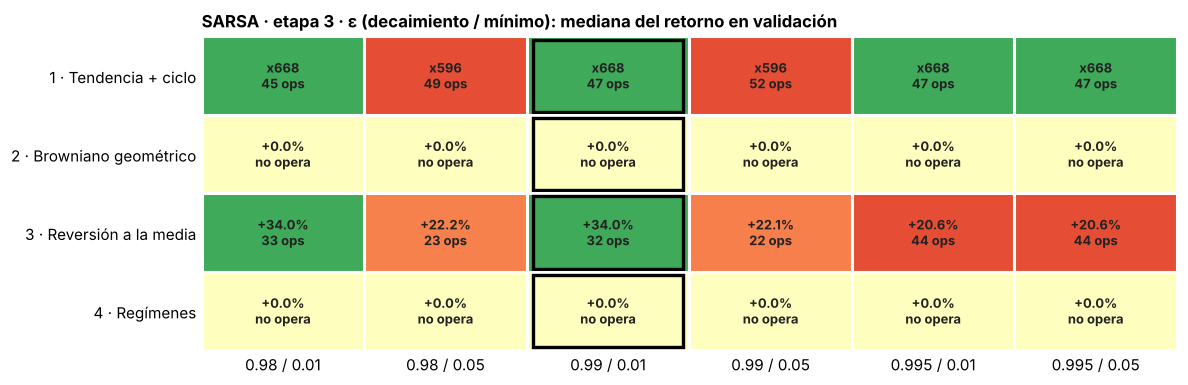

,alpha,gamma,epsilon_decay,epsilon_min
1 · Tendencia + ciclo,0.000500,0.000000,0.990000,0.010000
2 · Browniano geométrico,0.001000,0.900000,0.990000,0.010000
3 · Reversión a la media,0.000500,0.900000,0.990000,0.010000
4 · Regímenes,0.001000,0.900000,0.990000,0.010000


In [7]:
DECAYS, EPS_MIN = [0.98, 0.99, 0.995], [0.01, 0.05]
df_e, _, _ = grid({"epsilon_decay": DECAYS, "epsilon_min": EPS_MIN}, cfg2, "02_grid_epsilon")
sc_e = puntuar(df_e, ["epsilon_decay", "epsilon_min"])
cfg3 = elegir(df_e, sc_e, ["epsilon_decay", "epsilon_min"], cfg2)
sc_e["ε"] = sc_e.epsilon_decay.astype(str) + " / " + sc_e.epsilon_min.astype(str)
for m in MARKETS:
    cfg3[m]["ε"] = f"{cfg3[m]['epsilon_decay']} / {cfg3[m]['epsilon_min']}"
heatmap(sc_e, "ε", "SARSA · etapa 3 · ε (decaimiento / mínimo): mediana del retorno en validación", "02_ajuste_epsilon", elegido=cfg3)
for m in MARKETS:
    cfg3[m].pop("ε")
display(tabla_elegidos(cfg3, ["alpha", "gamma", "epsilon_decay", "epsilon_min"]).style.set_caption("Elegidos tras la etapa 3"))

**Ningún calendario supera al de partida (0,99 / 0,01) en la mayoría de semillas**, en ningún mercado. Pero hay un
detalle que distingue a SARSA de Q-Learning y que es justo lo que predice la teoría *on-policy*:

| Reversión a la media (validación) | ops/ep. con ε mín. 0,01 | ops/ep. con ε mín. 0,05 | Peor semilla con 0,05 |
|---|---|---|---|
| Q-Learning (01) | 32 | 30 | +34 % (igual que con 0,01) |
| **SARSA** | 32 | **22** | **+2,8 %** |

Si la exploración **no se apaga** (ε se queda en 5 %), SARSA aprende el valor de una política que seguirá equivocándose
un 5 % de las veces. Estar dentro le parece peor (puede vender por error y pagar comisión), así que **opera un tercio
menos** y en una semilla deja escapar casi todo el beneficio. Q-Learning, que usa el máximo, no se entera. Es la
versión "trading" de la ruta segura de *cliff walking* (slides3 p41). Con ε mínimo 0,01 el efecto desaparece, y por eso
el calendario elegido es el de partida.

## 6. Etapa 4 · Número de episodios y convergencia

Se entrena con 250, 500, 1 000 y 2 000 episodios. Las curvas de 2 000 episodios muestran **cuándo converge** cada
mercado: el punto marca el episodio en que la media móvil alcanza el 90 % de su mejora total (`convergence_episode`, D-0.3).

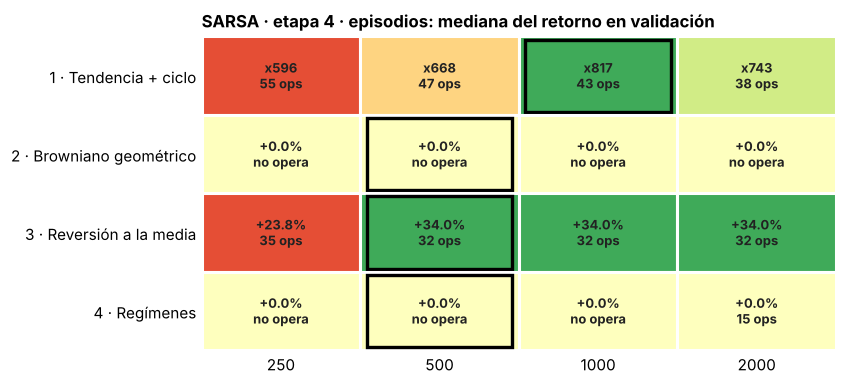

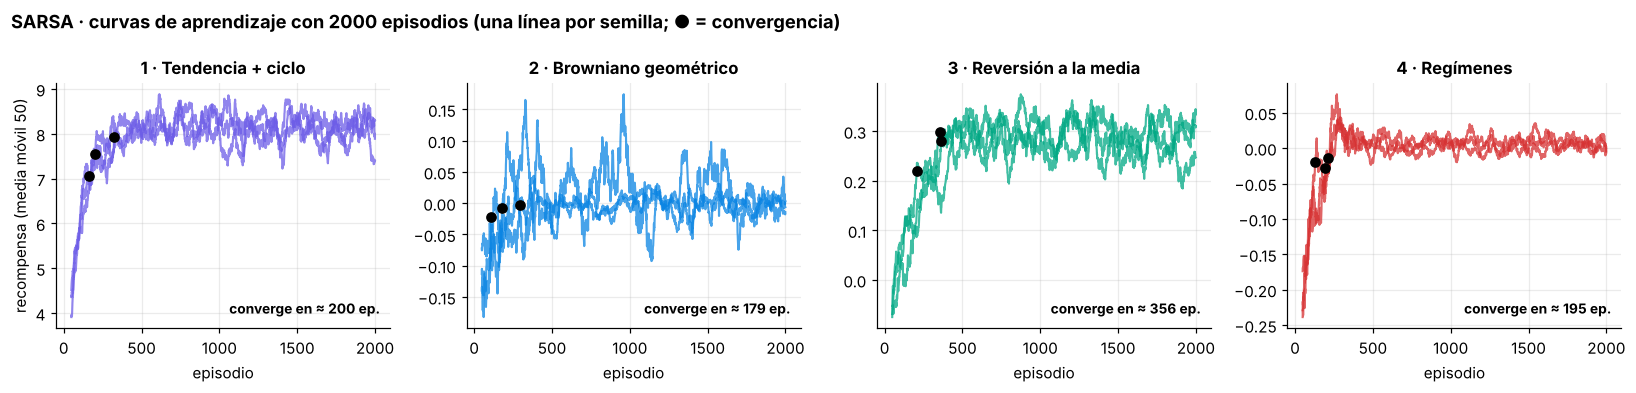

,"episodio de convergencia (mediana de 3 semillas, 2000 ep.)"
1 · Tendencia + ciclo,200
2 · Browniano geométrico,— (no opera)
3 · Reversión a la media,356
4 · Regímenes,195


,alpha,gamma,epsilon_decay,epsilon_min,n_episodes
1 · Tendencia + ciclo,0.000500,0.000000,0.990000,0.010000,1000.000000
2 · Browniano geométrico,0.001000,0.900000,0.990000,0.010000,500.000000
3 · Reversión a la media,0.000500,0.900000,0.990000,0.010000,500.000000
4 · Regímenes,0.001000,0.900000,0.990000,0.010000,500.000000


In [8]:
EPISODIOS = [20, 40] if QUICK else [250, 500, 1000, 2000]
df_n, curvas_n, _ = grid({"n_episodes": EPISODIOS}, cfg3, "02_grid_episodios")
sc_n = puntuar(df_n, ["n_episodes"])
cfg4 = elegir(df_n, sc_n, ["n_episodes"], cfg3)
heatmap(sc_n, "n_episodes", "SARSA · etapa 4 · episodios: mediana del retorno en validación", "02_ajuste_episodios", elegido=cfg4)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
largo = max(EPISODIOS)
for ax, m in zip(axes, MARKETS):
    sub = df_n[(df_n.mercado == m) & (df_n.n_episodes == largo)]
    for _, r in sub.iterrows():
        curva = pd.Series(curvas_n[r["id"]]).rolling(min(50, largo // 2)).mean()
        ax.plot(curva, color=MARKET_COLORS[m], alpha=0.75, lw=1.4)
        ce = min(int(r["episodios_convergencia"]), len(curva) - 1)
        ax.plot(ce, curva.iloc[ce], "o", color="black", ms=6, zorder=5)
    ax.set_title(MARKET_LABELS[m]); ax.set_xlabel("episodio")
    ax.text(0.97, 0.06, f"converge en ≈ {sub.episodios_convergencia.median():.0f} ep.", transform=ax.transAxes,
            ha="right", fontsize=9, weight="bold")
axes[0].set_ylabel("recompensa (media móvil 50)")
fig.suptitle(f"SARSA · curvas de aprendizaje con {largo} episodios (una línea por semilla; ● = convergencia)", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "02_curvas_convergencia"); plt.show()
conv = (df_n[df_n.n_episodes == largo].groupby("mercado")
        .agg(convergencia=("episodios_convergencia", "median"), ops=("n_trades", "mean")).reindex(list(MARKETS)))
conv["convergencia"] = [f"{c:.0f}" if o >= 0.5 else "— (no opera)" for c, o in zip(conv.convergencia, conv.ops)]
conv.index = [MARKET_LABELS[m] for m in conv.index]
display(conv[["convergencia"]].rename(columns={"convergencia": f"episodio de convergencia (mediana de {len(SEEDS)} semillas, {largo} ep.)"})
        .style.set_caption("Velocidad de convergencia de SARSA"))
display(tabla_elegidos(cfg4, ["alpha", "gamma", "epsilon_decay", "epsilon_min", "n_episodes"])
        .style.set_caption("Hiperparámetros finales de SARSA por mercado"))

**SARSA converge más despacio que Q-Learning** con 2 000 episodios y sus propios hiperparámetros: **≈ 200 episodios en el
mercado 1 (Q-Learning, 107) y ≈ 356 en reversión (Q-Learning, 262)**. En el mercado 1 compensa entrenar **1 000
episodios** en lugar de 500 (x816 frente a x667 en validación, gana en 2 de 3 semillas); en reversión, 500 bastan.

En los mercados 2 y 4 el agente no opera, así que la curva sube solo porque ε baja y deja de pagar comisiones
aleatorias: igual que en el 01, eso no es aprender una estrategia (en una semilla del mercado 4 con 2 000 episodios
aparece alguna operación, sin efecto en la mediana).

Esta comparación todavía mezcla dos cosas, el algoritmo y los hiperparámetros (γ distinto en reversión, α distinto en el
mercado 1). El §9 las separa con un duelo a configuración idéntica.

## 7. Resultado final en test

**Una sola vez**: cada mercado se entrena con sus hiperparámetros con **5 semillas** y se evalúa en las 200 series de
test, las mismas que los baselines y Q-Learning. La fila de `results/02_sarsa.csv` de cada mercado es la mediana de
las 5 semillas, y el detalle por semilla queda en `results/02_sarsa_semillas.csv`.

In [9]:
cfgs_final = [{**cfg4[m], "mercado": m, "seed": s, "split": "test"} for m in MARKETS for s in SEEDS_FINAL]
df_f, curvas_f, qs_f = run_grid(cfgs_final, "02_sarsa_semillas" + SUF, recompute=RECALCULAR)

num = ["retorno_mediana", "retorno_medio", "std", "sharpe", "max_drawdown", "n_trades", "episodios_convergencia", "tiempo_s"]
final = df_f.groupby("mercado")[num].median().reindex(list(MARKETS)).reset_index().assign(agente="sarsa")
if not QUICK:
    save_results(final.to_dict("records"), "02_sarsa")

comp = pd.concat([baselines, qlearning, final[RESULT_COLUMNS]])
tabla = comp.pivot(index="mercado", columns="agente", values="retorno_mediana").reindex(list(MARKETS))[["aleatorio", "buy_hold", "qlearning", "sarsa"]]
rango = df_f.groupby("mercado").retorno_mediana.agg(["min", "max"]).reindex(list(MARKETS))
tabla["SARSA semillas (mín – máx)"] = [f"{fmt_ret(a, m)} – {fmt_ret(b, m)}" for m, a, b in zip(rango.index, rango["min"], rango["max"])]
tabla["¿bate a B&H?"] = np.where(tabla.sarsa > tabla.buy_hold + 1e-9, "sí", "no")
tabla["ops/episodio"] = final.set_index("mercado").n_trades.round(0)
tabla.index = [MARKET_LABELS[m] for m in tabla.index]
display(tabla.style.format({c: "{:+.1%}" for c in ["aleatorio", "buy_hold", "qlearning", "sarsa"]})
        .map(lambda v: "color:#2F9E6E;font-weight:bold" if v == "sí" else "color:#D63031", subset=["¿bate a B&H?"])
        .set_caption(f"Mediana del retorno en test ({N_TEST} series) · SARSA y Q-Learning: mediana de {len(SEEDS_FINAL)} semillas"))

riesgo = comp[comp.agente.isin(["buy_hold", "qlearning", "sarsa"])].pivot(index="mercado", columns="agente",
                                                                          values=["sharpe", "max_drawdown"]).reindex(list(MARKETS))
nombres = {"buy_hold": "B&H", "qlearning": "Q-Learning", "sarsa": "SARSA"}
riesgo.columns = [f"{'Sharpe' if a == 'sharpe' else 'drawdown máx.'} · {nombres[c]}" for a, c in riesgo.columns]
riesgo.index = [MARKET_LABELS[m] for m in riesgo.index]
display(riesgo.style.format({c: ("{:.1%}" if "drawdown" in c else "{:+.3f}") for c in riesgo.columns})
        .set_caption("Riesgo en test: Sharpe por paso y caída máxima media (agentes: mediana de semillas)"))

agente,aleatorio,buy_hold,qlearning,sarsa,SARSA semillas (mín – máx),¿bate a B&H?,ops/episodio
1 · Tendencia + ciclo,+330.4%,+3261.7%,+50130.0%,+47063.0%,x472 – x502,sí,57.000000
2 · Browniano geométrico,-19.4%,-3.5%,+0.0%,+0.0%,+0.0% – +0.0%,sí,0.000000
3 · Reversión a la media,-17.2%,-0.3%,+27.0%,+27.0%,+15.8% – +27.0%,sí,29.000000
4 · Regímenes,-22.0%,-12.5%,+0.0%,+0.0%,+0.0% – +0.0%,sí,0.000000


,Sharpe · B&H,Sharpe · Q-Learning,Sharpe · SARSA,drawdown máx. · B&H,drawdown máx. · Q-Learning,drawdown máx. · SARSA
1 · Tendencia + ciclo,+0.115,+0.193,+0.192,89.5%,64.3%,64.3%
2 · Browniano geométrico,+0.001,+0.000,+0.000,41.3%,0.0%,0.0%
3 · Reversión a la media,+0.010,+0.041,+0.041,25.9%,19.6%,19.6%
4 · Regímenes,-0.011,+0.000,+0.000,45.0%,0.0%,0.0%


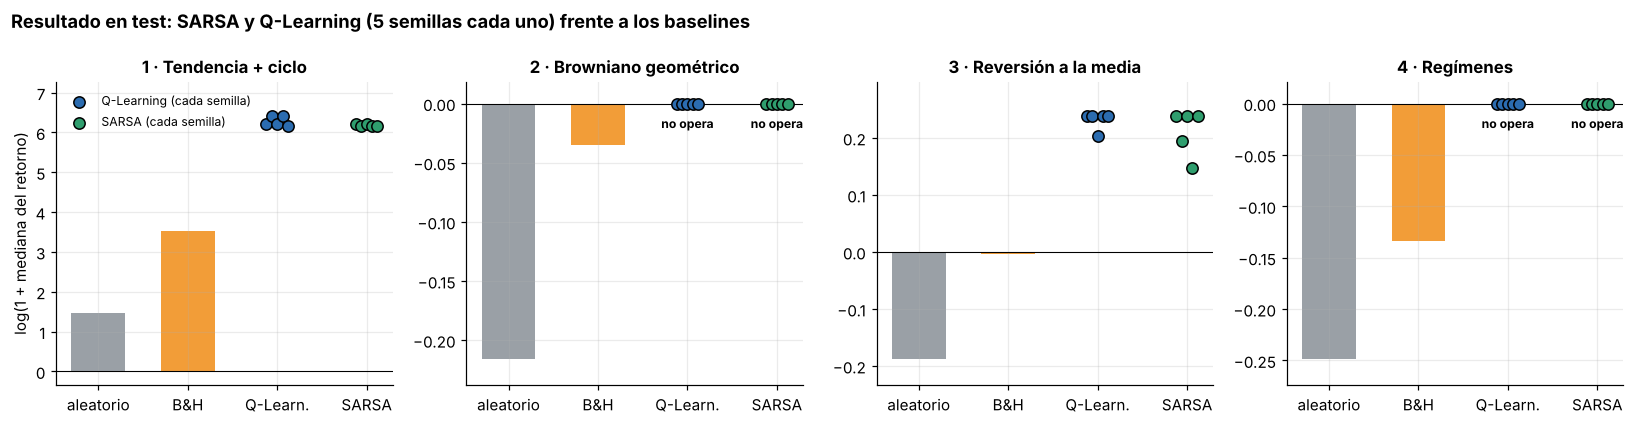

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, m in zip(axes, MARKETS):
    for x, a in [(0, "aleatorio"), (1, "buy_hold")]:
        v = baselines[(baselines.mercado == m) & (baselines.agente == a)].retorno_mediana.iloc[0]
        ax.bar(x, np.log1p(v), color=AGENT_COLORS[a], width=0.6)
    for x, (src_, ag_, lab) in [(2, (qlearning_sem, "qlearning", "Q-Learning")), (3, (df_f, "sarsa", "SARSA"))]:
        vals = src_[src_.mercado == m].retorno_mediana.to_numpy()
        ax.scatter(np.full(len(vals), x) + np.linspace(-0.12, 0.12, len(vals)), np.log1p(vals), s=55,
                   color=AGENT_COLORS[ag_], edgecolor="black", zorder=5, label=f"{lab} (cada semilla)")
        if np.all(np.abs(vals) < 1e-12):
            ax.annotate("no opera", (x, 0), xytext=(0, -16), textcoords="offset points", ha="center", fontsize=8, weight="bold")
    ax.axhline(0, color="black", lw=0.7)
    lo, hi = ax.get_ylim(); ax.set_ylim(lo - 0.05 * (hi - lo), hi + 0.08 * (hi - lo))
    ax.set_xticks([0, 1, 2, 3], ["aleatorio", "B&H", "Q-Learn.", "SARSA"]); ax.set_title(MARKET_LABELS[m])
axes[0].set_ylabel("log(1 + mediana del retorno)"); axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Resultado en test: SARSA y Q-Learning (5 semillas cada uno) frente a los baselines", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "02_resultado_test"); plt.show()

**SARSA llega al mismo sitio que Q-Learning.** En test (200 series, mediana de 5 semillas):

| Mercado | Buy & hold | Q-Learning | **SARSA** (semillas mín – máx) | Ops/ep. Q-L · SARSA |
|---|---|---|---|---|
| 1 · Tendencia + ciclo | x33,6 | x502 | **x471** (x471 – x502) | 48 · 57 |
| 2 · Browniano | −3,5 % | 0 % | **0 %** | 0 · 0 |
| 3 · Reversión a la media | −0,3 % | +27,0 % | **+27,0 %** (+15,8 – +27,0 %) | 29 · 29 |
| 4 · Regímenes | −12,5 % | 0 % | **0 %** | 0 · 0 |

- Varias semillas de SARSA dan **exactamente** las mismas cifras que Q-Learning (x501,3 en el mercado 1; +27,0 % en
  reversión, con el mismo Sharpe y la misma caída máxima). No es casualidad: con 20 estados y 3 acciones hay muy pocas
  políticas greedy posibles, y los dos algoritmos acaban en **la misma tabla de decisiones**.
- La diferencia está en la **dispersión entre semillas**: en reversión, la peor semilla de SARSA da +15,8 % y la de
  Q-Learning +22,5 %. El objetivo muestreado de SARSA es más ruidoso y algunas semillas se quedan en una política algo
  peor.
- Frente a buy & hold, SARSA gana por ≈ 14 veces en el mercado 1, gana por 27 puntos en reversión y "gana" en 2 y 4 por
  no operar (prudencia, no habilidad: 01 §8).

## 8. ¿Es la estrategia esperada?

Igual que en el 01: el **mapa de la política** de cada semilla (entra, se queda fuera, sale o sigue dentro según el bin
de tendencia) y **un episodio de test** con el agente de la semilla 0.

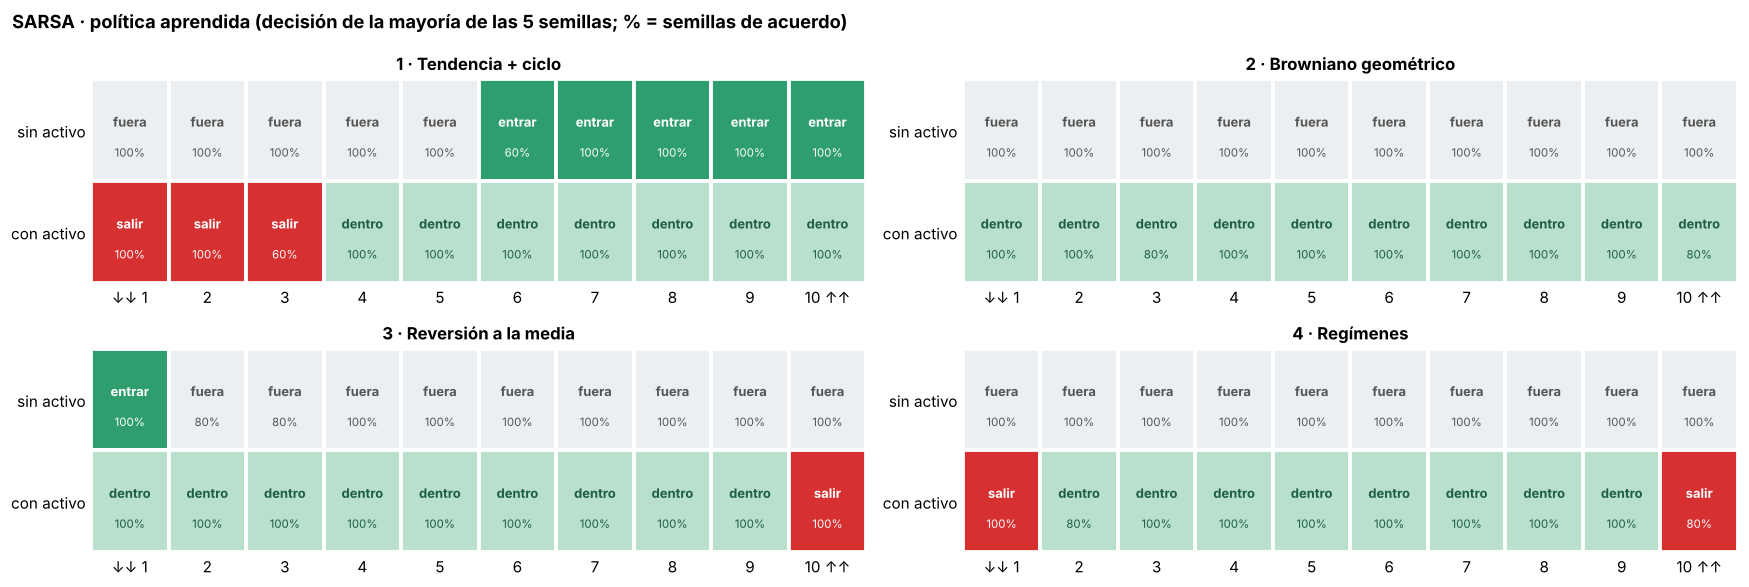

In [11]:
EFECTO = {(0, True): ("entrar", "#2F9E6E", "white"), (0, False): ("fuera", "#ECEFF1", "#555"),
          (1, True): ("salir", "#D63031", "white"), (1, False): ("dentro", "#B8E0CC", "#1E5E43")}
def politica(qs_por_semilla):
    return np.array([q.reshape(-1, 2, 3).argmax(axis=2) for q in qs_por_semilla])      # [semilla, bin, posición]

fig, axes = plt.subplots(2, 2, figsize=(16, 5.4))
for ax, m in zip(axes.ravel(), MARKETS):
    pols = politica([qs_f[i] for i in df_f[df_f.mercado == m].id])
    for b in range(pols.shape[1]):
        for pos in (0, 1):
            opera = (pols[:, b, pos] == (2 if pos == 0 else 0))
            mayoria = opera.mean() > 0.5
            txt, fc, tc = EFECTO[(pos, mayoria)]
            ax.add_patch(plt.Rectangle((b, 1 - pos), 1, 1, fc=fc, ec="white", lw=2.5))
            ax.text(b + 0.5, 1.58 - pos, txt, ha="center", va="center", fontsize=8.5, color=tc, weight="bold")
            ax.text(b + 0.5, 1.28 - pos, f"{max(opera.mean(), 1 - opera.mean()):.0%}", ha="center", va="center", fontsize=7.5, color=tc)
    nb_ = pols.shape[1]
    ax.set_xlim(0, nb_); ax.set_ylim(0, 2); ax.grid(False)
    ax.set_xticks(np.arange(nb_) + 0.5, ["↓↓ 1"] + [str(i) for i in range(2, nb_)] + [f"{nb_} ↑↑"])
    ax.set_yticks([0.5, 1.5], ["con activo", "sin activo"]); ax.set_title(MARKET_LABELS[m])
    for s_ in ax.spines.values(): s_.set_visible(False)
    ax.tick_params(length=0)
fig.suptitle(f"SARSA · política aprendida (decisión de la mayoría de las {len(SEEDS_FINAL)} semillas; % = semillas de acuerdo)",
             x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "02_politica_final"); plt.show()

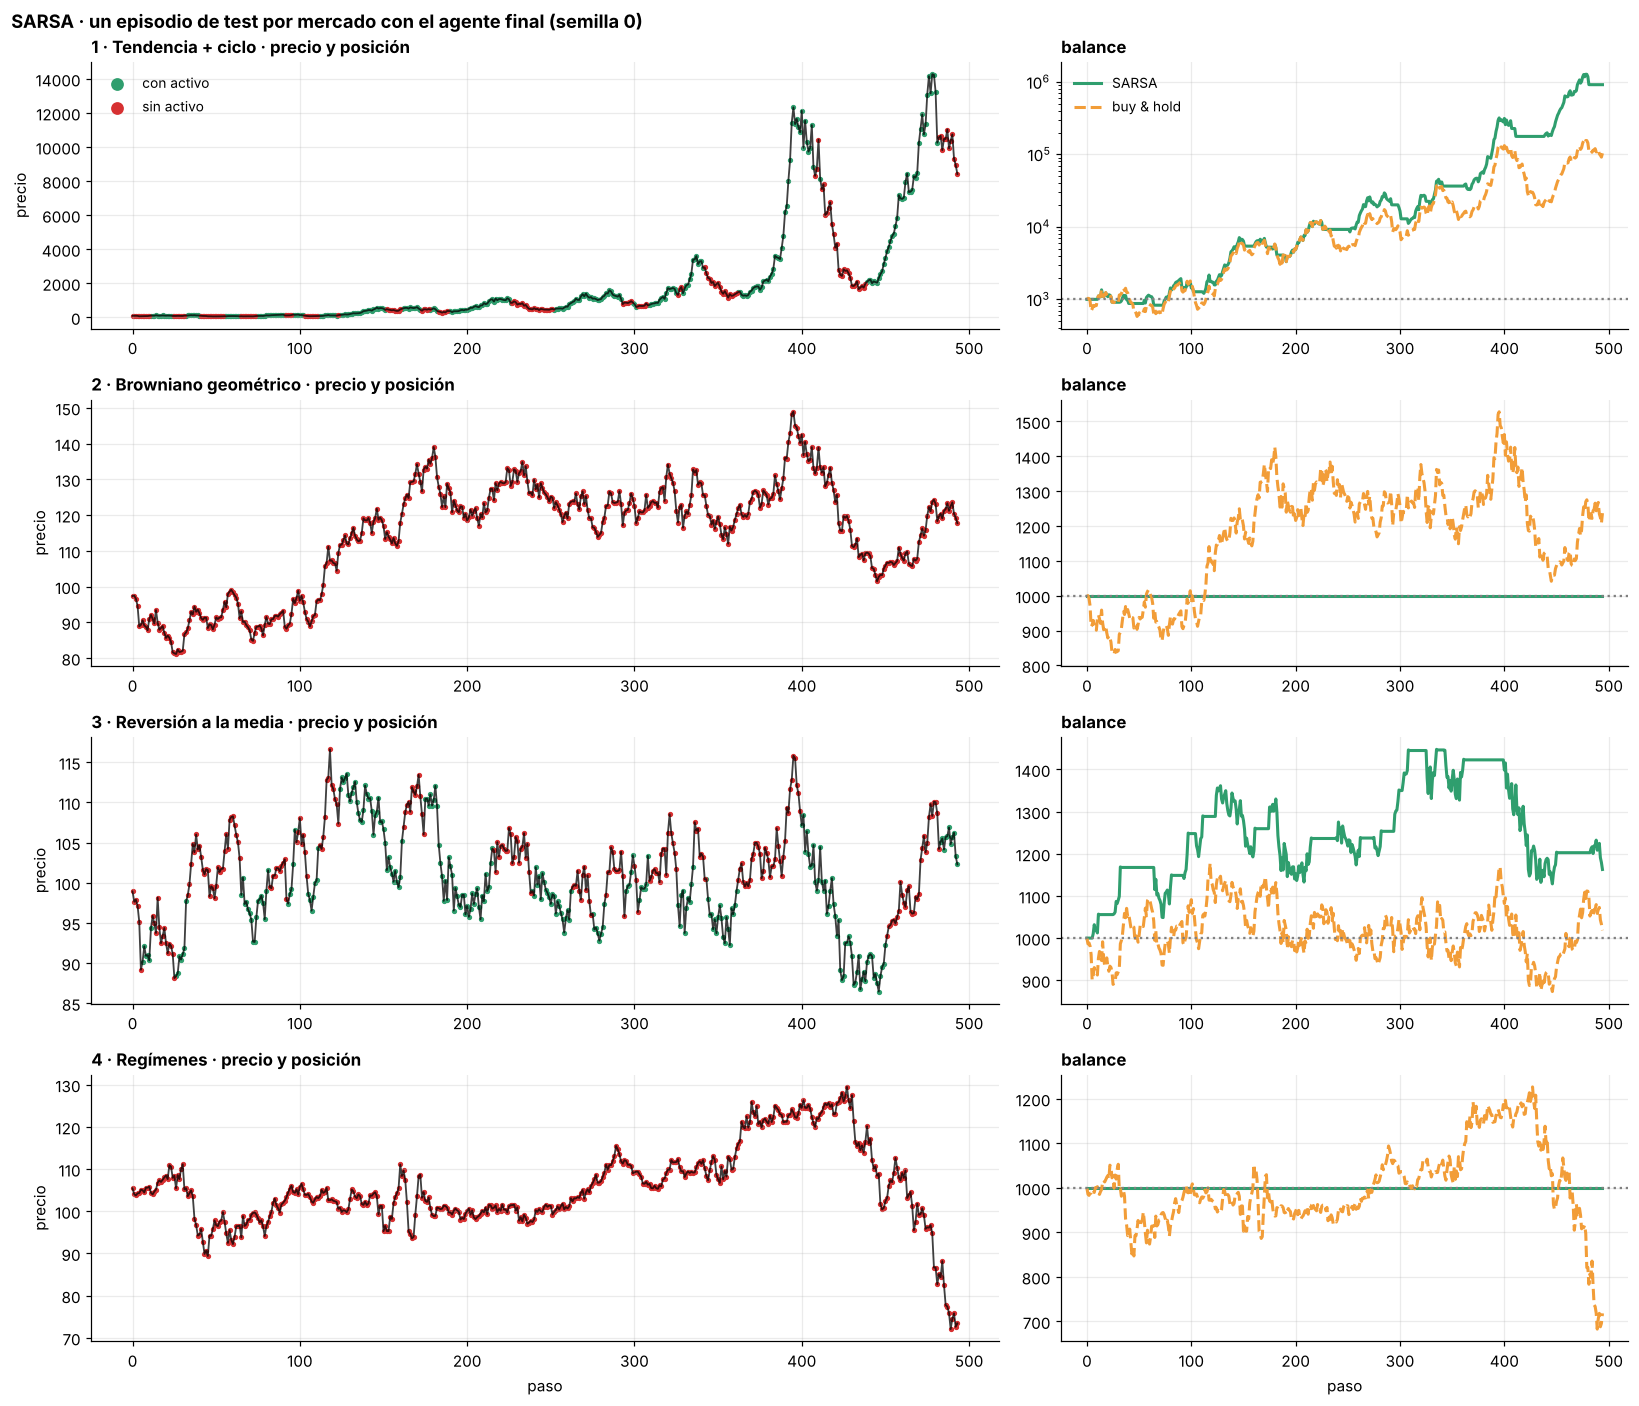

In [12]:
fig, axes = plt.subplots(4, 2, figsize=(15, 13), gridspec_kw={"width_ratios": [1.6, 1]})
for i, m in enumerate(MARKETS):
    cfg = cfg4[m]
    ag = SarsaAgent(edges=quantile_edges(m, cfg["n_bins"]), alpha=cfg["alpha"], gamma=cfg["gamma"])
    ag.Q = qs_f[df_f[(df_f.mercado == m) & (df_f.seed == 0)].id.iloc[0]].copy()
    prices = make_prices(m, 500, 100_000)                       # primera serie de test
    _, bal, _, pos = run_episode(SimpleTradingEnv(prices), ag, learn=False, greedy=True)
    vp = prices[5:-1]
    ax = axes[i, 0]
    ax.plot(vp, color="black", lw=1.2, alpha=0.75)
    ax.scatter(np.where(pos == 1)[0], vp[pos == 1], s=6, color="#2F9E6E", label="con activo")
    ax.scatter(np.where(pos == 0)[0], vp[pos == 0], s=6, color="#D63031", label="sin activo")
    ax.set_title(f"{MARKET_LABELS[m]} · precio y posición", loc="left"); ax.set_ylabel("precio")
    ax = axes[i, 1]
    ax.plot(bal, color=AGENT_COLORS["sarsa"], lw=2, label="SARSA")
    ax.plot(1000 * 0.999 / prices[5] * prices[5:], color=AGENT_COLORS["buy_hold"], ls="--", lw=2, label="buy & hold")
    ax.axhline(1000, color="gray", ls=":")
    ax.set_title("balance", loc="left"); ax.set_yscale("log" if m == "tendencia_ciclo" else "linear")
axes[0, 0].legend(loc="upper left", markerscale=3); axes[0, 1].legend(loc="upper left")
axes[-1, 0].set_xlabel("paso"); axes[-1, 1].set_xlabel("paso")
fig.suptitle("SARSA · un episodio de test por mercado con el agente final (semilla 0)", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "02_episodios_test"); plt.show()

**Lectura, mercado a mercado** (hipótesis del 00 §2 y resultado del 01 §8):

| Mercado | Qué ha aprendido SARSA | ¿Esperado? |
|---|---|---|
| **1 · Tendencia + ciclo** | Entra en los bins altos (6–10) y sale en los bajos (1–3), con una **banda de indiferencia** en 4–5 que ahorra comisiones. El bin 6 es el único dudoso (3 de 5 semillas entran) | ✅ Seguimiento de tendencia, la misma regla que Q-Learning |
| **2 · Browniano** | No entra nunca | ✅ No hay señal |
| **3 · Reversión a la media** | Compra solo tras la caída más fuerte (bin 1) y vende solo tras la subida más fuerte (bin 10) | ✅ Reversión de libro, idéntica a Q-Learning |
| **4 · Regímenes** | No entra nunca | ✅ Con este estado no compensa operar (01 §9: ninguna de 70 reglas simples bate a no operar) |

**Cuidado al leer la fila "con activo" en los mercados 2 y 4.** Como el agente greedy nunca entra, esos estados solo se
visitan al explorar y sus valores no importan en test (por ejemplo, el "salir" de los extremos en regímenes). Lo que
decide el comportamiento es la fila "sin activo".

## 9. SARSA frente a Q-Learning con la misma configuración

El profesor preguntará **qué algoritmo converge antes y por qué**. Comparar los dos resultados finales no basta,
porque cada uno tiene sus propios hiperparámetros. Aquí se entrenan **los dos con exactamente la misma configuración**
(la de partida común: α 0,001, γ 0,9, ε 0,99 / 0,01, con 1 000 episodios), las **mismas 3 semillas** y, por tanto,
las **mismas series de entrenamiento**. Lo único que cambia es el objetivo TD.

Se miden tres cosas:

1. **La recompensa *online*** durante el entrenamiento (la que obtiene mientras explora). Es lo que la teoría compara en
   *cliff walking* (slides3 p42): SARSA debería ir por encima mientras ε es alto.
2. **El episodio de convergencia** de esa curva (D-0.3).
3. **El resultado greedy en validación** al final, y cuánto opera cada uno.

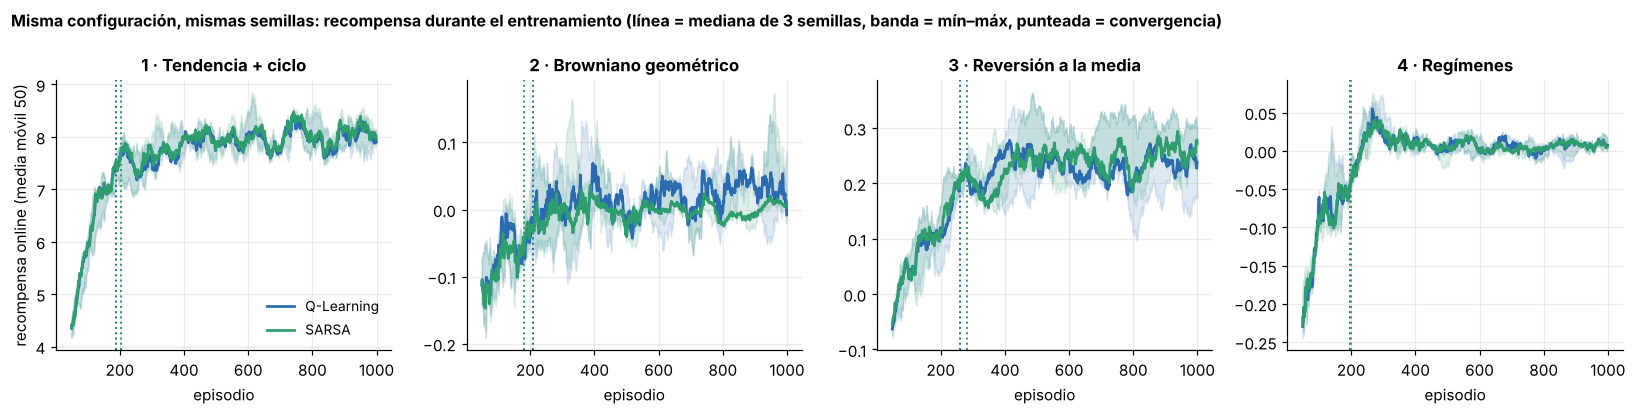

,online ep. 0–100 · Q-L,online ep. 0–100 · SARSA,online ep. 100–300 · Q-L,online ep. 100–300 · SARSA,online últimos 200 · Q-L,online últimos 200 · SARSA,convergencia (ep.) · Q-L,convergencia (ep.) · SARSA,validación (greedy) · Q-L,validación (greedy) · SARSA,ops/episodio · Q-L,ops/episodio · SARSA,tiempo (s) · Q-L,tiempo (s) · SARSA
mercado,,,,,,,,,,,,,,
1 · Tendencia + ciclo,+5.099,+5.144,+7.451,+7.525,+7.949,+8.030,189,203,+52589.8%,+50320.4%,66,56,18.9,18.8
2 · Browniano geométrico,-0.106,-0.116,-0.005,-0.003,+0.032,-0.002,207,179,+0.0%,+0.0%,0,0,19.0,18.2
3 · Reversión a la media,-0.020,-0.016,+0.158,+0.160,+0.244,+0.254,260,282,+22.2%,+22.6%,44,43,19.4,18.0
4 · Regímenes,-0.147,-0.153,-0.009,-0.020,+0.010,+0.010,197,199,+0.0%,+0.0%,0,0,19.0,18.2


In [13]:
N_DUELO = 40 if QUICK else 1000
duelo_cfgs = [{**BASE, "agente": ag_, "n_episodes": N_DUELO, "mercado": m, "seed": s}
              for m in MARKETS for ag_ in ["qlearning", "sarsa"] for s in SEEDS]
df_d, curvas_d, qs_d = run_grid(duelo_cfgs, "02_duelo" + SUF, recompute=RECALCULAR)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, m in zip(axes, MARKETS):
    for ag_, lab in [("qlearning", "Q-Learning"), ("sarsa", "SARSA")]:
        sub = df_d[(df_d.mercado == m) & (df_d.agente == ag_)]
        w = min(50, N_DUELO // 2)
        mat = np.array([pd.Series(curvas_d[i]).rolling(w).mean().to_numpy()[w - 1:] for i in sub.id])
        x = np.arange(w - 1, N_DUELO)
        ax.fill_between(x, mat.min(axis=0), mat.max(axis=0), color=AGENT_COLORS[ag_], alpha=0.15)
        ax.plot(x, np.median(mat, axis=0), color=AGENT_COLORS[ag_], lw=1.8, label=lab)
        ce = int(sub.episodios_convergencia.median()); ce = min(ce, N_DUELO - 1)
        ax.axvline(ce, color=AGENT_COLORS[ag_], ls=":", lw=1.3)
    ax.set_title(MARKET_LABELS[m]); ax.set_xlabel("episodio")
axes[0].set_ylabel("recompensa online (media móvil 50)"); axes[0].legend(loc="lower right")
fig.suptitle("Misma configuración, mismas semillas: recompensa durante el entrenamiento (línea = mediana de 3 semillas, "
             "banda = mín–máx, punteada = convergencia)", x=0.01, ha="left", weight="bold", fontsize=10.5)
fig.tight_layout(); savefig(fig, "02_duelo_curvas"); plt.show()

def online(curva, a, b): return np.mean(curva[a:b])
filas = []
for m in MARKETS:
    for ag_ in ["qlearning", "sarsa"]:
        sub = df_d[(df_d.mercado == m) & (df_d.agente == ag_)]
        cs = [curvas_d[i] for i in sub.id]
        filas.append({"mercado": MARKET_LABELS[m], "agente": ag_,
                      "online ep. 0–100": np.median([online(c, 0, 100) for c in cs]),
                      "online ep. 100–300": np.median([online(c, 100, 300) for c in cs]),
                      "online últimos 200": np.median([online(c, -200, None) for c in cs]),
                      "convergencia (ep.)": sub.episodios_convergencia.median(),
                      "validación (greedy)": sub.retorno_mediana.median(),
                      "ops/episodio": sub.n_trades.mean(),
                      "tiempo (s)": sub.tiempo_s.median()})
duelo = pd.DataFrame(filas).pivot(index="mercado", columns="agente").reindex([MARKET_LABELS[m] for m in MARKETS])
duelo.columns = [f"{a} · {'Q-L' if b == 'qlearning' else 'SARSA'}" for a, b in duelo.columns]
cols = [c for k in ["online ep. 0–100", "online ep. 100–300", "online últimos 200", "convergencia (ep.)",
                    "validación (greedy)", "ops/episodio", "tiempo (s)"] for c in duelo.columns if c.startswith(k)]
fmt = {c: ("{:+.3f}" if c.startswith("online") else "{:+.1%}" if c.startswith("valid") else "{:.0f}" if c.startswith(("conv", "ops")) else "{:.1f}") for c in cols}
display(duelo[cols].style.format(fmt).set_caption(
    "Misma configuración (α 0,001 · γ 0,9 · ε 0,99/0,01 · 1 000 ep.): mediana de 3 semillas. "
    "Recompensa online = suma de recompensas por episodio de entrenamiento"))

**Respuesta a "¿qué algoritmo converge antes?": Q-Learning, por poco, y SARSA va algo mejor mientras explora.** Con la
misma configuración y las mismas series:

| Mercado | Convergencia Q-L · SARSA | Online ep. 0–100 Q-L · SARSA | Online últimos 200 Q-L · SARSA | Ops/ep. (greedy) Q-L · SARSA |
|---|---|---|---|---|
| 1 · Tendencia + ciclo | **189** · 203 | 5,10 · **5,14** | 7,95 · **8,03** | 66 · **56** |
| 3 · Reversión a la media | **260** · 282 | −0,020 · **−0,016** | 0,244 · **0,254** | 44 · 43 |

1. **Q-Learning converge antes** en los dos mercados que operan (un 7–8 % menos de episodios), y lo mismo pasa con los
   hiperparámetros de cada uno (§6: 107 frente a 200 y 262 frente a 356). Motivo: Q-Learning apunta desde el principio
   a la política greedy; SARSA persigue un **objetivo que se mueve** (el valor de una ε-greedy cuya ε va bajando) y que
   además es más ruidoso porque usa la acción muestreada.
2. **SARSA tiene algo más de recompensa *online***, como predice *cliff walking* (slides3 p42): su Q descuenta sus propios
   errores de exploración y opera menos (56 frente a 66 operaciones en el mercado 1).
3. **Pero las diferencias son pequeñas** (las bandas de las curvas se solapan casi del todo), mucho menores que en
   *cliff walking*. Hay dos razones:
   - **Un error de exploración cuesta poco aquí**: una comisión del 0,1 % y un paso de exposición, frente a −100 por
     caer al acantilado.
   - **ε decae a 0,01** hacia el episodio 460: con un 99 % de acciones greedy, $Q(S',A') \approx \max_a Q(S',a)$ y los dos
     objetivos coinciden. Por eso acaban en la misma política (§7).

El §5 muestra el contraejemplo: cuando la exploración **no** se apaga (ε mínimo 0,05), la diferencia sí aparece, y
SARSA se vuelve claramente más conservador que Q-Learning.

## 10. Conclusiones

### Resultado final (test, 200 series, mediana de 5 semillas)

| Mercado | Aleatorio | Buy & hold | Q-Learning (01) | **SARSA** | Ops/ep. | Converge en (§6) | Estrategia |
|---|---|---|---|---|---|---|---|
| 1 · Tendencia + ciclo | x4,3 | x33,6 | x502 | **x471** (x471–x502) | 57 | 200 ep. (Q-L 107) | Sigue la tendencia, con banda de indiferencia |
| 2 · Browniano | −19,4 % | −3,5 % | 0 % | **0 %** | 0 | — | No opera (no hay señal) |
| 3 · Reversión a la media | −17,2 % | −0,3 % | +27,0 % | **+27,0 %** (+15,8 – +27,0 %) | 29 | 356 ep. (Q-L 262) | Compra en el extremo bajista y vende en el alcista |
| 4 · Regímenes | −22,0 % | −12,5 % | 0 % | **0 %** | 0 | — | No opera (límite del estado, 01 §9) |

### Lo que hemos aprendido

| # | Hallazgo | Evidencia |
|---|---|---|
| 1 | **SARSA y Q-Learning aprenden la misma estrategia** en los cuatro mercados; varias semillas producen exactamente la misma política y las mismas cifras en test. Con 20 estados × 3 acciones hay pocas políticas posibles | §7, §8 |
| 2 | **Q-Learning converge antes**: 189 frente a 203 episodios (mercado 1) y 260 frente a 282 (reversión) con la misma configuración; 107 frente a 200 y 262 frente a 356 con los hiperparámetros de cada uno. SARSA persigue un objetivo móvil y más ruidoso | §6, §9 |
| 3 | **SARSA es más conservador mientras explora**: algo más de recompensa online y menos operaciones. El efecto es pequeño porque un error cuesta solo un 0,1 % y ε decae a 0,01, pero se dispara si ε no se apaga: con ε mínimo 0,05 opera un tercio menos en reversión y una semilla cae a +2,8 % | §5, §9 |
| 4 | **SARSA es menos estable entre semillas** (peor semilla en reversión: +15,8 % frente a +22,5 %), coherente con la mayor varianza de su objetivo | §7 |
| 5 | **α todavía más pequeño** (0,0005 en los mercados 1 y 3) y **γ = 0 en el mercado 1**, igual que Q-Learning | §3, §4 |
| 6 | **Necesita más episodios** en el mercado 1 (1 000 frente a 500) para alcanzar el mismo nivel | §6 |

### Hiperparámetros finales por mercado

| Mercado | α | γ | ε (decaimiento / mínimo) | Episodios |
|---|---|---|---|---|
| 1 · Tendencia + ciclo | 0,0005 | 0 | 0,99 / 0,01 | 1 000 |
| 2 · Browniano | 0,001 | 0,9 | 0,99 / 0,01 | 500 |
| 3 · Reversión a la media | 0,0005 | 0,9 | 0,99 / 0,01 | 500 |
| 4 · Regímenes | 0,001 | 0,9 | 0,99 / 0,01 | 500 |

En los mercados 2 y 4 se mantienen los valores de partida porque el agente no opera con ninguna combinación (regla de
parsimonia del §2).

### Para el 04

- `results/02_sarsa.csv` tiene el mismo esquema que `01_qlearning.csv`. **Ojo con la columna `episodios_convergencia`**
  del test final: cada algoritmo usa sus propios hiperparámetros y en reversión sale al revés (Q-L 350, SARSA 292, porque
  Q-Learning usa γ = 0,5). Para la pregunta "¿quién converge antes?" la cifra justa es la del **duelo (§9)** o la de las
  curvas de 2 000 episodios (§6).
- Figura recomendada para el informe: `02_duelo_curvas.png` (o la tabla del §9) junto a la de convergencia del 01.
- `tiempo_s` no es comparable entre el 01 y el 02: se ejecutaron en máquinas distintas. Por paso, los dos algoritmos
  cuestan lo mismo (ver tiempos del duelo, misma máquina).